[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/erickmunoz-univalle/erickmunoz-fisica-computacional-2026ii-univalle/blob/main/Radiaci%C3%B3n_Cuerpo_Negro/taller8_colab.ipynb)

# Taller 8 de  Física Computacional
Solución de Taller 8 del taller de física computacional.

**Estudiante:** Erick Alexander Muñoz Orozco

**Lenguaje:** Fortran 2008 y Python

**Tema:** La radiación de cuerpo negro



---



In [22]:
# Comprueba gfortran (y lo instala en Colab si falta) y crea la carpeta del Taller
!which gfortran > /dev/null || (apt-get -qq update && apt-get -qq install -y gfortran > /dev/null)
!gfortran --version | head -1
!mkdir -p taller_cuerpo_negro
import os
os.makedirs("/content/taller_cuerpo_negro", exist_ok=True)
%cd /content/taller_cuerpo_negro

GNU Fortran (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
/content/taller_cuerpo_negro


**Parte B. Constante de Wien**

Modulos para ceros

In [23]:
%%writefile modulo_ceros.f90
! ==============================================================================
! Módulo: modulo_ceros
! Asignatura: Física Computacional (106018C) - Taller 8
! Descripción: Implementa la función trascendente asociada a la ley de
!              desplazamiento de Wien, su primera derivada y tres métodos
!              numéricos de búsqueda de raíces (Bisección, Newton-Raphson y
!              Secante) en doble precisión.
! Autor: Erick Alexander Muñoz Orozco
! Fecha: 14/11/2026
! ==============================================================================
module modulo_ceros
  implicit none

  ! ----------------------------------------------------------------------------
  ! Parámetros globales de precisión y control iterativo
  ! ----------------------------------------------------------------------------
  integer, parameter :: dp       = kind(1.0d0) ! Doble precisión (64 bits)
  integer, parameter :: max_iter = 100           ! Límite máximo de iteraciones

contains

  ! ----------------------------------------------------------------------------
  ! Función: f_wien
  ! Entradas: x (variable adimensional hc / (lambda * k_B * T)) [real(dp)]
  !           n (exponente del espectro: n = 5 en lambda, n = 3 en nu) [integer]
  ! Salida:   valor de F(x) = x - n * (1 - exp(-x)) [real(dp)]
  ! ----------------------------------------------------------------------------
  pure function f_wien(x, n) result(res)
    real(dp), intent(in) :: x
    integer, intent(in)  :: n
    real(dp)             :: res

    res = x - real(n, dp) * (1.0_dp - exp(-x))
  end function f_wien

  ! ----------------------------------------------------------------------------
  ! Función: df_wien
  ! Entradas: x (variable adimensional) [real(dp)]
  !           n (exponente del espectro) [integer]
  ! Salida:   primera derivada F'(x) = 1 - n * exp(-x) [real(dp)]
  ! ----------------------------------------------------------------------------
  pure function df_wien(x, n) result(res)
    real(dp), intent(in) :: x
    integer, intent(in)  :: n
    real(dp)             :: res

    res = 1.0_dp - real(n, dp) * exp(-x)
  end function df_wien

  ! ----------------------------------------------------------------------------
  ! Subrutina: biseccion
  ! Entradas: a_in, b_in (extremos del intervalo inicial [a, b]) [real(dp)]
  !           n (parámetro de la función de Wien) [integer]
  !           tol (tolerancia de convergencia epsilon) [real(dp)]
  ! Salidas:  raiz (aproximación al cero de F(x)) [real(dp)]
  !           iter (número de iteraciones realizadas) [integer]
  !           historial (vector con las estimaciones c_k de cada paso) [real(dp)]
  ! Descripción: Encuentra una raíz en [a, b] mediante bisección sucesiva.
  !              Verifica previamente el cambio de signo (Teorema de Bolzano)
  !              y detiene la búsqueda cuando b - c <= tol o tras 100 pasos.
  ! ----------------------------------------------------------------------------
  subroutine biseccion(a_in, b_in, n, tol, raiz, iter, historial)
    real(dp), intent(in)  :: a_in, b_in, tol
    integer, intent(in)   :: n
    real(dp), intent(out) :: raiz
    integer, intent(out)  :: iter
    real(dp), intent(out) :: historial(max_iter)

    ! Variables locales del intervalo y evaluaciones
    real(dp) :: a, b, c, fa, fb, fc

    ! Inicialización del estado
    a         = a_in
    b         = b_in
    fa        = f_wien(a, n)
    fb        = f_wien(b, n)
    iter      = 0
    historial = 0.0_dp

    ! Comprobación de cambio de signo antes de iterar
    if (fa * fb >= 0.0_dp) then
      print *, "Error (Biseccion): No hay cambio de signo en el intervalo inicial."
      raiz = 0.0_dp
      return
    end if

    ! Ciclo iterativo de reducción del intervalo
    do while (iter < max_iter)
      iter            = iter + 1
      c               = 0.5_dp * (a + b)
      historial(iter) = c
      fc              = f_wien(c, n)

      ! Criterio de parada por semi-ancho del intervalo o raíz exacta
      if (b - c <= tol .or. fc == 0.0_dp) then
        raiz = c
        return
      end if

      ! Selección del subintervalo que conserva el cambio de signo
      if (fa * fc < 0.0_dp) then
        b  = c
        fb = fc
      else
        a  = c
        fa = fc
      end if
    end do

    raiz = c
    print *, "Advertencia (Biseccion): Se alcanzo el maximo de 100 iteraciones sin converger."
  end subroutine biseccion

  ! ----------------------------------------------------------------------------
  ! Subrutina: newton
  ! Entradas: x0 (estimación inicial) [real(dp)]
  !           n (parámetro de la función de Wien) [integer]
  !           tol (tolerancia de convergencia epsilon) [real(dp)]
  ! Salidas:  raiz (aproximación al cero de F(x)) [real(dp)]
  !           iter (número de iteraciones realizadas) [integer]
  !           historial (vector con las estimaciones x_k de cada paso) [real(dp)]
  ! Descripción: Aplica el método de Newton-Raphson x_{k+1} = x_k - F(x_k)/F'(x_k).
  !              Se detiene con mensaje si F'(x_k) es nula o si |x_{k+1} - x_k| < tol.
  ! ----------------------------------------------------------------------------
  subroutine newton(x0, n, tol, raiz, iter, historial)
    real(dp), intent(in)  :: x0, tol
    integer, intent(in)   :: n
    real(dp), intent(out) :: raiz
    integer, intent(out)  :: iter
    real(dp), intent(out) :: historial(max_iter)

    ! Variables locales de iteración y evaluación
    real(dp) :: x_curr, x_next, fx, dfx

    ! Inicialización del estado
    x_curr    = x0
    iter      = 0
    historial = 0.0_dp

    ! Ciclo iterativo de aproximación tangencial
    do while (iter < max_iter)
      fx  = f_wien(x_curr, n)
      dfx = df_wien(x_curr, n)

      ! Protección contra división por cero (derivada nula)
      if (abs(dfx) <= tiny(1.0_dp)) then
        print *, "Error (Newton): Derivada nula. Deteniendo ejecucion."
        raiz = x_curr
        return
      end if

      iter            = iter + 1
      x_next          = x_curr - fx / dfx
      historial(iter) = x_next

      ! Criterio de parada por diferencia entre iteraciones consecutivas
      if (abs(x_next - x_curr) < tol) then
        raiz = x_next
        return
      end if

      x_curr = x_next
    end do

    raiz = x_curr
    print *, "Advertencia (Newton): Se alcanzo el maximo de 100 iteraciones sin converger."
  end subroutine newton

  ! ----------------------------------------------------------------------------
  ! Subrutina: secante
  ! Entradas: x0_in, x1_in (dos puntos iniciales distintos) [real(dp)]
  !           n (parámetro de la función de Wien) [integer]
  !           tol (tolerancia de convergencia epsilon) [real(dp)]
  ! Salidas:  raiz (aproximación al cero de F(x)) [real(dp)]
  !           iter (número de iteraciones realizadas) [integer]
  !           historial (vector con las estimaciones x_{k+1} de cada paso) [real(dp)]
  ! Descripción: Aproxima la derivada mediante diferencias finitas entre dos
  !              iteraciones previas. Se detiene con mensaje si f(x1) - f(x0) = 0
  !              o cuando |x_{k+1} - x_k| < tol.
  ! ----------------------------------------------------------------------------
  subroutine secante(x0_in, x1_in, n, tol, raiz, iter, historial)
    real(dp), intent(in)  :: x0_in, x1_in, tol
    integer, intent(in)   :: n
    real(dp), intent(out) :: raiz
    integer, intent(out)  :: iter
    real(dp), intent(out) :: historial(max_iter)

    ! Variables locales de puntos, evaluaciones y denominador
    real(dp) :: x0, x1, x2, f0, f1, denom

    ! Inicialización del estado
    x0        = x0_in
    x1        = x1_in
    f0        = f_wien(x0, n)
    f1        = f_wien(x1, n)
    iter      = 0
    historial = 0.0_dp

    ! Ciclo iterativo de aproximación secante
    do while (iter < max_iter)
      denom = f1 - f0

      ! Protección contra denominador nulo
      if (abs(denom) <= tiny(1.0_dp)) then
        print *, "Error (Secante): Denominador nulo (f(x1) - f(x0) = 0). Deteniendo."
        raiz = x1
        return
      end if

      iter            = iter + 1
      x2              = x1 - f1 * (x1 - x0) / denom
      historial(iter) = x2

      ! Criterio de parada por diferencia entre iteraciones consecutivas
      if (abs(x2 - x1) < tol) then
        raiz = x2
        return
      end if

      ! Desplazamiento de puntos para la siguiente iteración
      x0 = x1
      f0 = f1
      x1 = x2
      f1 = f_wien(x1, n)
    end do

    raiz = x1
    print *, "Advertencia (Secante): Se alcanzo el maximo de 100 iteraciones sin converger."
  end subroutine secante

end module modulo_ceros

Overwriting modulo_ceros.f90


Programa wien

In [24]:
%%writefile programa_wien.f90
! ==============================================================================
! Programa: programa_wien
! Asignatura: Física Computacional (106018C) - Taller 8 (Parte B)
! Descripción: Calcula las raíces adimensionales x_5 y x_3 de la ley de
!              desplazamiento de Wien mediante Bisección, Newton-Raphson y
!              Secante, evalúa la constante de Wien b y exporta los resultados
!              e historiales de convergencia a archivos .dat.
! Autor: Erick Alexander Muñoz Orozco
! Fecha: 16/11/2026
! ==============================================================================
program programa_wien
  use modulo_ceros
  implicit none

  ! ----------------------------------------------------------------------------
  ! Constantes físicas exactas del Sistema Internacional (SI) y tolerancia
  ! ----------------------------------------------------------------------------
  real(dp), parameter :: h   = 6.62607015e-34_dp ! Constante de Planck [J s]
  real(dp), parameter :: c   = 299792458.0_dp    ! Rapidez de la luz en el vacío [m/s]
  real(dp), parameter :: kB  = 1.380649e-23_dp   ! Constante de Boltzmann [J/K]
  real(dp), parameter :: tol = 1.0e-10_dp        ! Tolerancia de convergencia

  ! ----------------------------------------------------------------------------
  ! Variables de trabajo y unidades de entrada/salida
  ! ----------------------------------------------------------------------------
  real(dp) :: raiz, x5_newton, x3_newton, b_wien
  real(dp) :: hist(max_iter)
  integer  :: iter, k
  integer  :: u_res, u_iter, u_const

  ! Apertura de archivos de salida para resultados e historial
  open(newunit=u_res,  file="resultado_wien.dat",   status="replace", action="write")
  open(newunit=u_iter, file="iteraciones_wien.dat", status="replace", action="write")

  ! ----------------------------------------------------------------------------
  ! Bloque 1: Cálculo de x_5 (espectro por longitud de onda, n = 5)
  !           Registra tanto el resumen como el historial iteración a iteración
  ! ----------------------------------------------------------------------------

  ! Método 1: Bisección en [1, 10]
  call biseccion(1.0_dp, 10.0_dp, 5, tol, raiz, iter, hist)
  write(u_res, '(i4, i4, es24.16, i6)') 5, 1, raiz, iter
  do k = 1, iter
    write(u_iter, '(i4, i6, es24.16)') 1, k, hist(k)
  end do

  ! Método 2: Newton-Raphson con x0 = 10
  call newton(10.0_dp, 5, tol, raiz, iter, hist)
  x5_newton = raiz
  write(u_res, '(i4, i4, es24.16, i6)') 5, 2, raiz, iter
  do k = 1, iter
    write(u_iter, '(i4, i6, es24.16)') 2, k, hist(k)
  end do

  ! Método 3: Secante con x0 = 10, x1 = 9
  call secante(10.0_dp, 9.0_dp, 5, tol, raiz, iter, hist)
  write(u_res, '(i4, i4, es24.16, i6)') 5, 3, raiz, iter
  do k = 1, iter
    write(u_iter, '(i4, i6, es24.16)') 3, k, hist(k)
  end do

  ! ----------------------------------------------------------------------------
  ! Bloque 2: Cálculo de x_3 (espectro por frecuencia, n = 3)
  ! ----------------------------------------------------------------------------

  ! Método 1: Bisección en [1, 10]
  call biseccion(1.0_dp, 10.0_dp, 3, tol, raiz, iter, hist)
  write(u_res, '(i4, i4, es24.16, i6)') 3, 1, raiz, iter

  ! Método 2: Newton-Raphson con x0 = 10
  call newton(10.0_dp, 3, tol, raiz, iter, hist)
  x3_newton = raiz
  write(u_res, '(i4, i4, es24.16, i6)') 3, 2, raiz, iter

  ! Método 3: Secante con x0 = 10, x1 = 9
  call secante(10.0_dp, 9.0_dp, 3, tol, raiz, iter, hist)
  write(u_res, '(i4, i4, es24.16, i6)') 3, 3, raiz, iter

  ! ----------------------------------------------------------------------------
  ! Bloque 3: Caso crítico de Newton para n = 5 con x0 = 0.5 (Método 4)
  !           Evalúa la atracción hacia la raíz trivial x = 0 cuando x0 < ln(5)
  ! ----------------------------------------------------------------------------
  call newton(0.5_dp, 5, tol, raiz, iter, hist)
  write(u_res, '(i4, i4, es24.16, i6)') 5, 4, raiz, iter

  close(u_res)
  close(u_iter)

  ! ----------------------------------------------------------------------------
  ! Bloque 4: Cálculo y exportación de la constante de desplazamiento de Wien
  !           b = (h * c) / (k_B * x_5)
  ! ----------------------------------------------------------------------------
  b_wien = (h * c) / (kB * x5_newton)

  open(newunit=u_const, file="constante_wien.dat", status="replace", action="write")
  write(u_const, '(3es24.16)') x5_newton, x3_newton, b_wien
  close(u_const)

  ! ----------------------------------------------------------------------------
  ! Bloque 5: Salida de verificación por consola
  ! ----------------------------------------------------------------------------
  print *, "=========================================================="
  print *, " RESULTADOS PARTE B - LEY DE DESPLAZAMIENTO DE WIEN"
  print *, "=========================================================="
  print '(a, es24.16)', " x5 (Newton, x0=10)   = ", x5_newton
  print '(a, es24.16)', " x3 (Newton, x0=10)   = ", x3_newton
  print '(a, es24.16)', " Constante b [m K]    = ", b_wien
  print '(a, es24.16)', " Newton (n=5, x0=0.5) = ", raiz
  print *, "=========================================================="

end program programa_wien

Overwriting programa_wien.f90


In [25]:

!gfortran -fcheck=bounds -o programa_wien modulo_ceros.f90 programa_wien.f90 && ./programa_wien

  RESULTADOS PARTE B - LEY DE DESPLAZAMIENTO DE WIEN
 x5 (Newton, x0=10)   =   4.9651142317442769E+00
 x3 (Newton, x0=10)   =   2.8214393721220792E+00
 Constante b [m K]    =   2.8977719551851722E-03
 Newton (n=5, x0=0.5) =   8.9452237883628477E-17


**Parte C. Constante de Stefan-Boltzmann**

Modulo romberg taller 7

In [33]:
%%writefile modulo_romberg.f90
! ==============================================================================
! Módulo: modulo_romberg
! Asignatura: Física Computacional (106018C) - Taller 8 (Parte C)
! Descripción: Implementa la integración numérica mediante el método de
!              Romberg (regla del trapecio compuesto + extrapolación de
!              Richardson) en doble precisión, junto con los integrandos de
!              la ley de Stefan-Boltzmann con y sin cambio de variable.
! Autor: Erick Alexander Muñoz Orozco
! Fecha: 16/11/2026
! ==============================================================================
module modulo_romberg
  implicit none

  ! ----------------------------------------------------------------------------
  ! Parámetros globales de precisión y control de niveles de Romberg
  ! ----------------------------------------------------------------------------
  integer, parameter :: dp    = kind(1.0d0) ! Doble precisión (64 bits)
  integer, parameter :: k_max = 20            ! Nivel máximo de refinamiento (2^20 + 1 pts)

contains

  ! ----------------------------------------------------------------------------
  ! Función: integrando_sin_cambio
  ! Entrada:  x (variable adimensional en [0, inf)) [real(dp)]
  ! Salida:   f(x) = x^3 / (exp(x) - 1) [real(dp)]
  ! Descripción: Evalúa el integrando de Stefan-Boltzmann en su variable
  !              original, garantizando el límite exacto f(0) = 0 y evitando
  !              desbordamiento exponencial para x muy grande.
  ! ----------------------------------------------------------------------------
  pure function integrando_sin_cambio(x) result(res)
    real(dp), intent(in) :: x
    real(dp)             :: res

    if (x <= 0.0_dp .or. x > 700.0_dp) then
      res = 0.0_dp
    else
      res = (x**3) / (exp(x) - 1.0_dp)
    end if
  end function integrando_sin_cambio

  ! ----------------------------------------------------------------------------
  ! Función: integrando_con_cambio
  ! Entrada:  t (variable transformada en el intervalo finito [0, 1]) [real(dp)]
  ! Salida:   g(t) = [x(t)^3 / (exp(x(t)) - 1)] * [1 / (1 - t)^2] [real(dp)]
  ! Descripción: Mapea x = t / (1 - t) sobre [0, 1] e impone los límites
  !              analíticos g(0) = 0 y g(1) = 0 en los extremos del intervalo.
  ! ----------------------------------------------------------------------------
  pure function integrando_con_cambio(t) result(res)
    real(dp), intent(in) :: t
    real(dp)             :: res
    real(dp)             :: x, one_minus_t

    ! Límites exactos en los extremos t = 0 y t = 1
    if (t <= 0.0_dp .or. t >= 1.0_dp) then
      res = 0.0_dp
      return
    end if

    one_minus_t = 1.0_dp - t
    x           = t / one_minus_t

    ! Evita overflow en exp(x) cuando t es extremadamente cercano a 1
    if (x > 700.0_dp) then
      res = 0.0_dp
    else
      res = ((x**3) / (exp(x) - 1.0_dp)) / (one_minus_t**2)
    end if
  end function integrando_con_cambio

  ! ----------------------------------------------------------------------------
  ! Función: evaluar_integrando
  ! Entradas: u (punto de evaluación) [real(dp)]
  !           modo (1 = con cambio de variable en [0,1];
  !                 2 = sin cambio de variable en [0,100]) [integer]
  ! Salida:   valor del integrando seleccionado en u [real(dp)]
  ! ----------------------------------------------------------------------------
  pure function evaluar_integrando(u, modo) result(res)
    real(dp), intent(in) :: u
    integer, intent(in)  :: modo
    real(dp)             :: res

    if (modo == 1) then
      res = integrando_con_cambio(u)
    else
      res = integrando_sin_cambio(u)
    end if
  end function evaluar_integrando

  ! ----------------------------------------------------------------------------
  ! Subrutina: integrar_romberg
  ! Entradas: a, b (límites de integración) [real(dp)]
  !           tol (tolerancia de convergencia) [real(dp)]
  !           modo (selector de integrando: 1 con cambio, 2 sin cambio) [integer]
  ! Salidas:  integral (valor estimado R(k,k)) [real(dp)]
  !           k_final (nivel final alcanzado) [integer]
  !           n_eval (número total de evaluaciones de función: 2^k_final + 1) [integer]
  ! ----------------------------------------------------------------------------
  subroutine integrar_romberg(a, b, tol, modo, integral, k_final, n_eval)
    real(dp), intent(in)  :: a, b, tol
    integer, intent(in)   :: modo
    real(dp), intent(out) :: integral
    integer, intent(out)  :: k_final, n_eval

    ! Tabla de Romberg y variables auxiliares
    real(dp) :: R(0:k_max, 0:k_max)
    real(dp) :: h, suma, x_i, factor4
    integer  :: k, j, i, n_sub

    R = 0.0_dp

    ! Nivel k = 0: Regla del trapecio simple con 1 subintervalo (2 evaluaciones)
    h       = b - a
    R(0, 0) = 0.5_dp * h * (evaluar_integrando(a, modo) + evaluar_integrando(b, modo))

    ! Refinamiento sucesivo de niveles k = 1, ..., k_max
    do k = 1, k_max
      h     = 0.5_dp * h
      n_sub = 2**(k - 1)
      suma  = 0.0_dp

      ! Suma únicamente los puntos nuevos impares para reutilizar evaluaciones previas
      do i = 1, n_sub
        x_i  = a + real(2*i - 1, dp) * h
        suma = suma + evaluar_integrando(x_i, modo)
      end do

      ! Trapecio compuesto en el nivel k
      R(k, 0) = 0.5_dp * R(k - 1, 0) + h * suma

      ! Extrapolación de Richardson para eliminar términos de error O(h^(2j))
      factor4 = 1.0_dp
      do j = 1, k
        factor4 = 4.0_dp * factor4
        R(k, j) = R(k, j - 1) + (R(k, j - 1) - R(k - 1, j - 1)) / (factor4 - 1.0_dp)
      end do

      ! Criterio de parada por convergencia diagonal
      if (abs(R(k, k) - R(k - 1, k - 1)) < tol) then
        k_final  = k
        n_eval   = 2**k + 1
        integral = R(k, k)
        return
      end if
    end do

    ! Si alcanza el límite máximo de niveles sin satisfacer tol
    k_final  = k_max
    n_eval   = 2**k_max + 1
    integral = R(k_max, k_max)
    print *, "Advertencia (Romberg): Se alcanzo el nivel maximo k_max sin converger."
  end subroutine integrar_romberg

end module modulo_romberg

Overwriting modulo_romberg.f90


Programa sigma

In [34]:
%%writefile programa_sigma.f90
! ==============================================================================
! Programa: programa_sigma
! Asignatura: Física Computacional (106018C) - Taller 8 (Parte C)
! Descripción: Calcula la integral adimensional de Planck I y la constante de
!              Stefan-Boltzmann sigma mediante integración de Romberg en dos
!              regímenes: (1) con cambio de variable x = t/(1 - t) en [0, 1] y
!              (2) directamente sobre [0, 100] sin cambio de variable. Exporta
!              los resultados a resultado_sigma.dat y los compara con pi^4/15.
! Autor: Erick Alexander Muñoz Orozco
! Fecha: 16/11/2026
! ==============================================================================
program programa_sigma
  use modulo_romberg
  implicit none

  ! ----------------------------------------------------------------------------
  ! Constantes físicas exactas del Sistema Internacional (SI) y tolerancia
  ! ----------------------------------------------------------------------------
  real(dp), parameter :: h   = 6.62607015e-34_dp         ! Constante de Planck [J s]
  real(dp), parameter :: c   = 299792458.0_dp            ! Rapidez de la luz [m/s]
  real(dp), parameter :: kB  = 1.380649e-23_dp           ! Constante de Boltzmann [J/K]
  real(dp), parameter :: pi  = acos(-1.0_dp)             ! Número pi en doble precisión
  real(dp), parameter :: tol = 1.0e-8_dp                 ! Tolerancia de integración

  ! ----------------------------------------------------------------------------
  ! Variables de resultados y unidades de archivo
  ! ----------------------------------------------------------------------------
  real(dp) :: pref_sigma, I_exacta, sigma_exacta
  real(dp) :: I_cambio, sigma_cambio
  real(dp) :: I_directa, sigma_directa
  integer  :: k_cambio, eval_cambio
  integer  :: k_directa, eval_directa
  integer  :: u_out

  ! Prefactor físico de la constante de Stefan-Boltzmann: (2 * pi * kB^4) / (h^3 * c^2)
  pref_sigma   = (2.0_dp * pi * (kB**4)) / ((h**3) * (c**2))
  I_exacta     = (pi**4) / 15.0_dp
  sigma_exacta = pref_sigma * I_exacta

  ! ----------------------------------------------------------------------------
  ! Bloque 1: Integración con cambio de variable en t in [0, 1] (modo = 1)
  ! ----------------------------------------------------------------------------
  call integrar_romberg(0.0_dp, 1.0_dp, tol, 1, I_cambio, k_cambio, eval_cambio)
  sigma_cambio = pref_sigma * I_cambio

  ! ----------------------------------------------------------------------------
  ! Bloque 2: Integración directa sin cambio de variable en x in [0, 100] (modo = 2)
  ! ----------------------------------------------------------------------------
  call integrar_romberg(0.0_dp, 100.0_dp, tol, 2, I_directa, k_directa, eval_directa)
  sigma_directa = pref_sigma * I_directa

  ! ----------------------------------------------------------------------------
  ! Bloque 3: Exportación de resultados a resultado_sigma.dat
  !           Columnas: k_final, evaluaciones, integral, sigma
  ! ----------------------------------------------------------------------------
  open(newunit=u_out, file="resultado_sigma.dat", status="replace", action="write")
  write(u_out, '(i6, i10, 2es24.16)') k_cambio,  eval_cambio,  I_cambio,  sigma_cambio
  write(u_out, '(i6, i10, 2es24.16)') k_directa, eval_directa, I_directa, sigma_directa
  close(u_out)

  ! ----------------------------------------------------------------------------
  ! Bloque 4: Comparación con el valor analítico exacto en consola
  ! ----------------------------------------------------------------------------
  print *, "========================================================================="
  print *, " RESULTADOS PARTE C - CONSTANTE DE STEFAN-BOLTZMANN (ROMBERG)"
  print *, "========================================================================="
  print '(a, es24.16)', " Valor exacto I = pi^4/15      = ", I_exacta
  print '(a, es24.16)', " Valor exacto sigma [W/m^2K^4] = ", sigma_exacta
  print *, "-------------------------------------------------------------------------"
  print '(a, i4, a, i8)', " [1] Con cambio [0, 1]   -> k = ", k_cambio,  ", eval = ", eval_cambio
  print '(a, es24.16, a, es12.4)', "     I_num = ", I_cambio,  " | Error abs = ", abs(I_cambio - I_exacta)
  print '(a, es24.16)',            "     sigma = ", sigma_cambio
  print *, "-------------------------------------------------------------------------"
  print '(a, i4, a, i8)', " [2] Sin cambio [0, 100] -> k = ", k_directa, ", eval = ", eval_directa
  print '(a, es24.16, a, es12.4)', "     I_num = ", I_directa, " | Error abs = ", abs(I_directa - I_exacta)
  print '(a, es24.16)',            "     sigma = ", sigma_directa
  print *, "========================================================================="

end program programa_sigma

Overwriting programa_sigma.f90


In [35]:
!gfortran -fcheck=bounds -o programa_sigma modulo_romberg.f90 programa_sigma.f90 && ./programa_sigma

  RESULTADOS PARTE C - CONSTANTE DE STEFAN-BOLTZMANN (ROMBERG)
 Valor exacto I = pi^4/15      =   6.4939394022668280E+00
 Valor exacto sigma [W/m^2K^4] =   5.6703744191844307E-08
 -------------------------------------------------------------------------
 [1] Con cambio [0, 1]   -> k =   10, eval =     1025
     I_num =   6.4939394022670962E+00 | Error abs =   2.6823E-13
     sigma =   5.6703744191846650E-08
 -------------------------------------------------------------------------
 [2] Sin cambio [0, 100] -> k =    1, eval =        3
     I_num =   1.6072915399699316E-15 | Error abs =   6.4939E+00
     sigma =   1.4034539387964817E-23


Al comparar ambos resultados con el valor analítico $\frac{\pi ^{4}}{15}$, observamos que la integración con cambio de variable converge con alta precisión y un error mínimo. Por el contrario, en la integración sin cambio de variable, el integrando concentra la mayor parte de su área en una región muy acotada y decae exponencialmente en el resto del dominio. Debido a este comportamiento, el algoritmo se detiene prematuramente en la tercera evaluación: al iniciar en una zona donde los valores son extremadamente pequeños, la diferencia entre iteraciones consecutivas resulta insignificante frente al criterio de tolerancia absoluta, provocando una falsa convergencia.


**Parte D. Máximo del espectro solar**

In [36]:

%%writefile maximo_espectro.py
# ==============================================================================
# Script: maximo_espectro.py
# Asignatura: Física Computacional (106018C) - Taller 8 (Parte D)
# Descripción: Modela la radiancia espectral solar (T = 5772 K) mediante la ley
#              de Planck sobre mallas uniformes en [100, 3000] nm para cuatro
#              pasos (100, 50, 25 y 12.5 nm). Determina el pico de emisión por
#              tres métodos (máximo discreto, spline de derivada central y
#              derivada del spline de B_lambda), evalúa el error frente a la ley
#              de Wien y genera maximo_espectro.dat y espectro_solar.png.
# Autor: Erick Alexander Muñoz Orozco
# Fecha: 16/11/2026
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

# ------------------------------------------------------------------------------
# 1. Constantes físicas exactas del Sistema Internacional (SI) y parámetros
# ------------------------------------------------------------------------------
H_PLANCK = 6.62607015e-34   # Constante de Planck [J s]
C_LUZ    = 299792458.0      # Rapidez de la luz en el vacío [m/s]
K_BOLTZ  = 1.380649e-23     # Constante de Boltzmann [J/K]
T_SOL    = 5772.0           # Temperatura efectiva del Sol [K]


# ------------------------------------------------------------------------------
# 2. Función de radiancia espectral de Planck B_lambda(lambda, T)
# ------------------------------------------------------------------------------
def radiancia_planck(lam_nm: np.ndarray, temp: float) -> np.ndarray:
    """
    Calcula la radiancia espectral B_lambda [W m^-2 sr^-1 m^-1] dada la longitud
    de onda en nanómetros (lam_nm) y la temperatura en Kelvin (temp).
    """
    lam_m = lam_nm * 1.0e-9
    x = (H_PLANCK * C_LUZ) / (lam_m * K_BOLTZ * temp)
    prefactor = (2.0 * H_PLANCK * C_LUZ**2) / (lam_m**5)
    return prefactor / np.expm1(x)


# ------------------------------------------------------------------------------
# 3. Selección de raíz válida (concavidad negativa y cercanía al máximo discreto)
# ------------------------------------------------------------------------------
def seleccionar_maximo(raices: np.ndarray, d2_func, lam_ref: float) -> float:
    """
    Filtra las raíces donde la segunda derivada es negativa (máximo local) y
    devuelve la más cercana a lam_ref para descartar oscilaciones espurias.
    """
    candidatos = [r for r in raices if d2_func(r) < 0.0]
    if len(candidatos) == 0:
        return lam_ref
    candidatos = np.array(candidatos, dtype=float)
    idx_cercano = int(np.argmin(np.abs(candidatos - lam_ref)))
    return float(candidatos[idx_cercano])


# ------------------------------------------------------------------------------
# 4. Lectura de la constante de Wien y valores de referencia teóricos
# ------------------------------------------------------------------------------
datos_wien = np.loadtxt("constante_wien.dat")
x5_wien = float(datos_wien[0])
x3_wien = float(datos_wien[1])
b_wien  = float(datos_wien[2])

lam_max_wien_nm = (b_wien / T_SOL) * 1.0e9
lam_nu_max_nm   = (H_PLANCK * C_LUZ / (K_BOLTZ * T_SOL * x3_wien)) * 1.0e9


# ------------------------------------------------------------------------------
# 5. Barrido sobre los pasos de malla y cálculo por los tres métodos
# ------------------------------------------------------------------------------
pasos_dlam = [100.0, 50.0, 25.0, 12.5]
resultados = []

# Variables para almacenar la malla de 25 nm destinada a la gráfica
lam_25 = None
B_25 = None
lam_max_25_c = None

print("=" * 84)
print(" RESULTADOS PARTE D - MÁXIMO DEL ESPECTRO SOLAR (T = 5772 K)")
print(f" Referencia Wien lambda_max = {lam_max_wien_nm:.6f} nm | "
      f"lambda(nu_max) = {lam_nu_max_nm:.6f} nm")
print("=" * 84)
print(f"{'dlam [nm]':>10} | {'err (a) [nm]':>15} | {'err (b) [nm]':>15} | {'err (c) [nm]':>15}")
print("-" * 84)

for dlam in pasos_dlam:
    # Malla uniforme en [100, 3000] nm
    lam = np.arange(100.0, 3000.0 + 0.5 * dlam, dlam, dtype=float)
    B = radiancia_planck(lam, T_SOL)

    # Método (a): mayor valor del arreglo discreto
    idx_max = int(np.argmax(B))
    lam_a = float(lam[idx_max])

    # Método (b): cero del spline de la derivada central
    lam_int = lam[1:-1]
    dB_central = (B[2:] - B[:-2]) / (2.0 * dlam)
    spline_dB = CubicSpline(lam_int, dB_central)
    raices_b = spline_dB.roots(extrapolate=False)
    lam_b = seleccionar_maximo(raices_b, spline_dB.derivative(1), lam_a)

    # Método (c): cero de la derivada del spline de B_lambda
    spline_B = CubicSpline(lam, B)
    dspline_B = spline_B.derivative(1)
    d2spline_B = spline_B.derivative(2)
    raices_c = dspline_B.roots(extrapolate=False)
    lam_c = seleccionar_maximo(raices_c, d2spline_B, lam_a)

    # Errores absolutos en nm respecto a lambda_max = b / T
    err_a = abs(lam_a - lam_max_wien_nm)
    err_b = abs(lam_b - lam_max_wien_nm)
    err_c = abs(lam_c - lam_max_wien_nm)

    resultados.append((dlam, err_a, err_b, err_c))
    print(f"{dlam:10.1f} | {err_a:15.6e} | {err_b:15.6e} | {err_c:15.6e}")

    # Guardar datos de la malla de 25 nm para la figura
    if np.isclose(dlam, 25.0):
        lam_25 = lam
        B_25 = B
        lam_max_25_c = lam_c

print("=" * 84)


# ------------------------------------------------------------------------------
# 6. Exportación de errores a maximo_espectro.dat (formato es24.16)
# ------------------------------------------------------------------------------
with open("maximo_espectro.dat", "w", encoding="utf-8") as f_out:
    for fila in resultados:
        f_out.write(f"{fila[0]:24.16e}{fila[1]:24.16e}{fila[2]:24.16e}{fila[3]:24.16e}\n")


# ------------------------------------------------------------------------------
# 7. Generación de la figura espectro_solar.png (malla de 25 nm)
# ------------------------------------------------------------------------------
# Evaluamos también el spline continuo en [100, 3000] nm para visualizar la curva suave
lam_fino = np.linspace(100.0, 3000.0, 1000)
B_spline_fino = CubicSpline(lam_25, B_25)(lam_fino)

# Conversión de B_lambda de [W m^-2 sr^-1 m^-1] a [kW m^-2 sr^-1 nm^-1]
escala = 1.0e-12

fig, ax = plt.subplots(figsize=(9, 5.2), dpi=150)

ax.plot(lam_fino, B_spline_fino * escala, color="#1f4e78", lw=2.0,
        label=r"Spline cúbico de $B_\lambda(\lambda, 5772\ \mathrm{K})$")
ax.scatter(lam_25, B_25 * escala, color="#2e75b6", s=16, alpha=0.75, zorder=3,
           label=r"Malla discreta ($\Delta\lambda = 25\ \mathrm{nm}$)")

# Marcador de lambda_max (ley de Wien / spline)
B_max_val = float(radiancia_planck(np.array([lam_max_25_c]), T_SOL)[0]) * escala
ax.axvline(lam_max_25_c, color="#c0392b", linestyle="--", lw=1.6,
           label=rf"$\lambda_{{\max}}$ (spline) = {lam_max_25_c:.2f} nm (Wien: {lam_max_wien_nm:.2f} nm)")
ax.scatter([lam_max_25_c], [B_max_val], color="#c0392b", s=55, zorder=4)

# Marcador de lambda correspondiente al máximo en frecuencia (x_3)
B_nu_val = float(radiancia_planck(np.array([lam_nu_max_nm]), T_SOL)[0]) * escala
ax.axvline(lam_nu_max_nm, color="#27ae60", linestyle="-.", lw=1.6,
           label=rf"$\lambda(\nu_{{\max}}) = hc/(k_B T x_3)$ = {lam_nu_max_nm:.2f} nm")
ax.scatter([lam_nu_max_nm], [B_nu_val], color="#27ae60", s=55, zorder=4)

ax.set_title(r"Radiancia espectral de cuerpo negro solar ($T = 5772\ \mathrm{K}$)", fontsize=12.5, pad=10)
ax.set_xlabel(r"Longitud de onda $\lambda$ [nm]", fontsize=11)
ax.set_ylabel(r"Radiancia espectral $B_\lambda$ [$\mathrm{kW\ m^{-2}\ sr^{-1}\ nm^{-1}}$]", fontsize=11)
ax.set_xlim(100, 3000)
ax.set_ylim(bottom=0)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(frameon=True, fontsize=9.5, loc="upper right")

plt.tight_layout()
plt.savefig("espectro_solar.png", dpi=150)
plt.close("espectro_solar.png")

Overwriting maximo_espectro.py


 RESULTADOS PARTE D - MÁXIMO DEL ESPECTRO SOLAR (T = 5772 K)
 Referencia Wien lambda_max = 502.039493 nm | lambda(nu_max) = 883.479354 nm
 dlam [nm] |    err (a) [nm] |    err (b) [nm] |    err (c) [nm]
------------------------------------------------------------------------------------
     100.0 |    2.039493e+00 |    1.290250e+01 |    1.202125e+00
      50.0 |    2.039493e+00 |    3.393159e+00 |    3.215547e-02
      25.0 |    2.039493e+00 |    8.517028e-01 |    2.904589e-03
      12.5 |    2.039493e+00 |    2.131257e-01 |    3.127396e-04


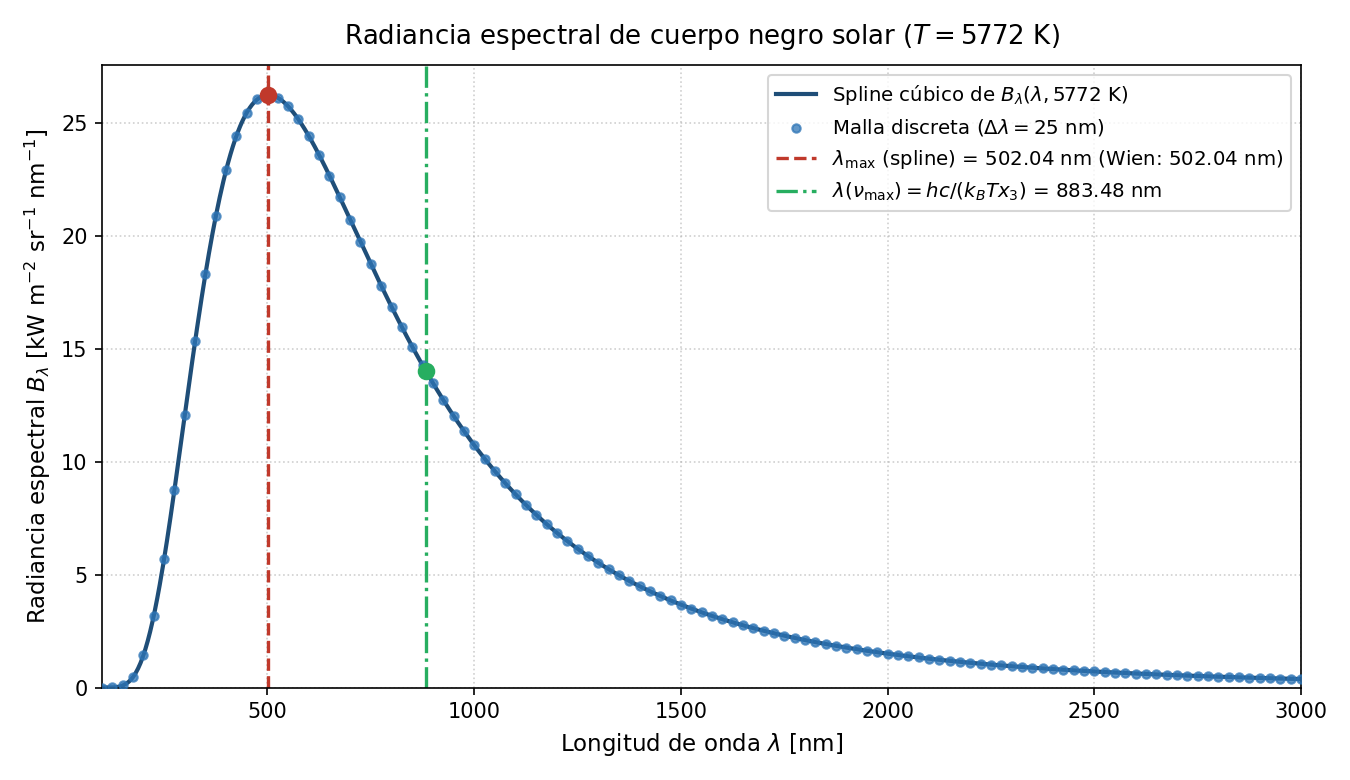

In [37]:
!python maximo_espectro.py
from IPython.display import Image, display
display(Image("espectro_solar.png"))

**Parte E. Preguntas de interpretación y reporte**

1. **Costo de los métodos.** Compare las iteraciones de los tres métodos con $n = 5$. Con `iteraciones_wien.dat`, estime el orden de Newton y de la secante.

In [38]:
import numpy as np

# 1. Orden de convergencia de Newton (2) y Secante (3) con iteraciones_wien.dat
iters = np.loadtxt("iteraciones_wien.dat")
res   = np.loadtxt("resultado_wien.dat")
x5_exact = res[1, 2]  # Raíz de Newton para n=5

for metodo, nombre in [(2, "Newton"), (3, "Secante")]:
    xs = iters[iters[:, 0] == metodo, 2]
    errs = np.abs(xs - x5_exact)
    errs = errs[errs > 1e-13]  # Filtrar piso de redondeo de máquina
    p = np.log(errs[2:] / errs[1:-1]) / np.log(errs[1:-1] / errs[:-2])
    print(f"{nombre}: iteraciones = {len(xs)}, órdenes p estimados = {np.round(p, 4)}")

# 4. Razones de reducción de error en maximo_espectro.dat
errs_d = np.loadtxt("maximo_espectro.dat")
print("\nRazones de reducción al dividir dlam entre 2:")
print("Método (b):", errs_d[:-1, 2] / errs_d[1:, 2])
print("Método (c):", errs_d[:-1, 3] / errs_d[1:, 3])

Newton: iteraciones = 4, órdenes p estimados = [1.9968]
Secante: iteraciones = 5, órdenes p estimados = [2.0455 1.4873]

Razones de reducción al dividir dlam entre 2:
Método (b): [3.80250298 3.98397052 3.99624635]
Método (c): [37.38478688 11.07057317  9.2875652 ]


Rta: Al comparar los tres métodos con $n = 5$ para una tolerancia $\varepsilon = 10^{-10}$, Bisección requiere 37 iteraciones (39 evaluaciones de $F$), Newton-Raphson 4 iteraciones (8 evaluaciones entre $F$ y $F'$) y Secante 5 iteraciones (7 evaluaciones de $F$). Esta diferencia se debe a sus órdenes de convergencia: Bisección tiene convergencia lineal ($p = 1$), reduciendo el error apenas a la mitad en cada paso; en cambio, a partir de iteraciones_wien.dat se estima un orden $p \approx 1.997$ para Newton (convergencia cuadrática teórica $p = 2$) y $p \approx 1.49$ para Secante (convergencia superlineal teórica $\phi \approx 1.618$). En términos de eficiencia, Secante logra el menor costo computacional total al requerir menos evaluaciones de función y no necesitar derivadas analíticas, Newton es el más rápido en número de pasos, y Bisección, aunque es el más lento, puede garantizar la convergencia si existe cambio de signo.

2. **Valor inicial.** ¿A qué valor llega Newton desde $x_0 = 0.5$? ¿Por qué es una raíz correcta de la ecuación, pero no la respuesta al problema físico?

Rta: Al iniciar en $x_0 = 0.5$ para $n = 5$, Newton converge a $x = 0$. Esta es una raíz matemáticamente correcta porque satisface $F(0) = 0 - 5(1 - e^0) = 0$ (y, al estar $x_0 = 0.5$ a la izquierda del mínimo de $F(x)$ en $x = \ln 5 \approx 1.61$, la pendiente negativa lleva la iteración hacia el origen). Sin embargo, no resuelve el problema físico porque buscamos el máximo de emisión: dado que $x = hc/(\lambda k_B T)$, el valor $x = 0$ corresponde al límite $\lambda \to \infty$, donde la radiancia $B_\lambda \propto x^5/(e^x - 1) \approx x^4$ se anula ($B_\lambda = 0$), representando el mínimo de emisión y no el pico del espectro.

3. **Parada prematura.** En la Parte C, ¿qué valor da Romberg en $[0, 100]$ y en qué nivel se detiene? Explique, con los puntos que evalúa en sus primeros niveles, por qué el criterio de la diagonal se cumple sin que la integral haya convergido. Proponga una comprobación adicional.

Rta: Al integrar directamente sobre $[0, 100]$, Romberg se detiene prematuramente en el nivel $k = 1$ (3 evaluaciones) arrojando un valor de $I \approx 1.61 \times 10^{-15}$ ($\sigma \approx 1.40 \times 10^{-23}\text{ W m}^{-2}\text{ K}^{-4}$), muy lejos del valor analítico $\pi^4/15 \approx 6.4939$. Esto ocurre porque el integrando $x^3/(e^x-1)$ concentra la mayor parte de su área cerca de $x \approx 2.82$ y decae exponencialmente en el resto del dominio: en $k = 0$ el algoritmo solo evalúa los extremos $x = 0$ y $x = 100$, y en $k = 1$ añade únicamente el punto medio $x = 50$. Como todos estos puntos caen en el origen o en la cola exponencial donde los valores son extremadamente pequeños ($\lesssim 10^{-17}$), la diferencia diagonal $\vert{}R_{1,1} - R_{0,0}\vert{}$ resulta insignificante frente a la tolerancia ($10^{-8}$), provocando una falsa convergencia antes de detectar el pico. Para evitarlo, basta exigir un nivel mínimo de refinamiento (por ejemplo, $k \ge 4$) o verificar que la tolerancia se cumpla en dos niveles consecutivos.

4. **Eslabón más débil.** En la Parte D, ¿con qué razón bajan los errores de (b) y de (c) al reducir $\Delta\lambda$ a la mitad? ¿Qué limita la precisión de (b)? ¿Por qué el error de (a) no baja en estas mallas?

Rta: Al reducir $\Delta\lambda$ a la mitad, el error de (b) baja por un factor de 4 (orden $\mathcal{O}(\Delta\lambda^2)$) y el de (c) por un factor cercano a 10 (orden $\mathcal{O}(\Delta\lambda^3)$, propio de la derivada de un spline cúbico). La precisión de (b) está limitada por el error $\mathcal{O}(\Delta\lambda^2)$ de las diferencias centrales usadas antes de interpolar, que actúa como el eslabón más débil. Por su parte, el error de (a) no baja (se mantiene en $2.04\text{ nm}$) porque $500\text{ nm}$ es nodo exacto en las cuatro mallas y sigue siendo el punto discreto más cercano al máximo real ($\sim 502.04\text{ nm}$).

5. **Dos máximos.** ¿Por qué el máximo en longitud de onda y el máximo en frecuencia no corresponden al mismo color? ¿Cuál de los dos es "el" color del Sol?

Rta: No coinciden porque $B_\lambda$ y $B_\nu$ miden la energía por unidad de longitud de onda y de frecuencia respectivamente; al convertir de una a otra mediante $\nu = c/\lambda$, los intervalos se estiran de forma no lineal ($\vert{}d\nu\vert{} = \frac{c}{\lambda^2}d\lambda$), desplazando el pico desde el verde-azul hacia el infrarrojo cercano. Ninguno de los dos es "el color del Sol" porque el ojo humano no percibe un solo pico, sino la mezcla de todo el espectro visible ($380\text{–}750\text{ nm}$), lo que resulta en luz blanca.

**Parte F. Verificación**

In [39]:
# ==================== VERIFICACIÓN DEL TALLER 8 Y 9 (no modificar) ====================
import os
import numpy as np
from scipy.interpolate import CubicSpline as _CS

H_, C_, KB_ = 6.62607015e-34, 299792458.0, 1.380649e-23

def raiz_referencia(n):
    x = float(n)
    for _ in range(200):
        x = n*(1 - np.exp(-x))
    return x

X5, X3 = raiz_referencia(5), raiz_referencia(3)
B_REF = H_*C_/(KB_*X5)
I_REF = np.pi**4/15
S_REF = 2*np.pi*KB_**4/(H_**3*C_**2)*I_REF
ITER_ESPERADAS = {(5,1):37, (5,2):4, (5,3):5,
                  (3,1):37, (3,2):5, (3,3):6}

_avisados = set()
def tabla(dat, fuentes, forma=None):
    for ruta in [dat, *fuentes]:
        if not os.path.isfile(ruta):
            raise ValueError(f"no existe {ruta}; ejecute desde la carpeta del taller")
    antiguos = [f for f in fuentes if os.path.getmtime(dat) < os.path.getmtime(f)]
    if antiguos and dat not in _avisados:
        print(f"[AVISO] {dat} parece anterior a su fuente; vuelva a generar si editó el código.")
        _avisados.add(dat)
    t = np.loadtxt(dat, ndmin=2)
    if forma is not None and t.shape != forma:
        raise ValueError(f"{dat}: forma {t.shape}; se espera {forma}")
    if not np.all(np.isfinite(t)):
        raise ValueError(f"{dat}: contiene NaN o infinitos")
    return t

def enteros(a, nombre):
    if not np.all(a == np.floor(a)):
        raise ValueError(f"{nombre}: se requieren valores enteros")

def resultados_wien():
    t = tabla('resultado_wien.dat', ['modulo_ceros.f90', 'programa_wien.f90'], (7,4))
    enteros(t[:,[0,1,3]], 'n, método e iteraciones')
    claves = [tuple(map(int, fila[:2])) for fila in t[:6]]
    if len(set(claves)) != 6 or set(claves) != set(ITER_ESPERADAS):
        raise ValueError('debe aparecer una vez cada combinación de n=5,3 y método=1,2,3')
    if tuple(t[6,:2]) != (5,4):
        raise ValueError('la fila 7 debe identificar n=5, método=4')
    if np.any((t[:,3] < 1) | (t[:,3] > 100)):
        raise ValueError('conteos fuera de 1 a 100')
    return t

def constantes():
    t = tabla('constante_wien.dat', ['modulo_ceros.f90', 'programa_wien.f90'], (1,3))[0]
    if abs(t[0]-X5)>2e-10 or abs(t[1]-X3)>2e-10:
        raise ValueError('x5 o x3 incorrectos en constante_wien.dat')
    if abs(t[2]-B_REF)/B_REF > 1e-9:
        raise ValueError('constante de Wien incorrecta')
    return t

resultados = []
def caso(nombre, funcion):
    try:
        detalle = funcion()
        ok = True
    except Exception as e:
        ok, detalle = False, str(e)
    resultados.append(ok)
    print(f"[{'PASS' if ok else 'FAIL'}] {nombre}" + (f" -> {detalle}" if detalle else ''))

def c1():
    t = resultados_wien()
    for n, m, raiz, it in t[:6]:
        ref = X5 if n == 5 else X3
        if abs(raiz-ref)>2e-10:
            raise ValueError(f'n={n:g}, método={m:g}: raíz incorrecta')
        esperado = ITER_ESPERADAS[int(n),int(m)]
        if it != esperado:
            raise ValueError(f'n={n:g}, método={m:g}: {it:g} iteraciones; se esperan {esperado}')
    return f'x5={X5:.10f}, x3={X3:.10f}; conteos correctos'

def historia_referencia(m):
    # Recurrencias independientes para verificar los registros de n=5.
    f = lambda x: x-5*(1-np.exp(-x))
    df = lambda x: 1-5*np.exp(-x)
    a,b,prev = 1.0,10.0,10.0
    x = {1:0., 2:10., 3:9.}[m]
    valores=[]
    for _ in range(ITER_ESPERADAS[5,m]):
        if m==1:
            z=(a+b)/2
            if f(a)*f(z)<=0: b=z
            else: a=z
        elif m==2: z=x-f(x)/df(x)
        else: z=x-f(x)*(x-prev)/(f(x)-f(prev))
        valores.append(z)
        prev,x=x,z
    return np.array(valores)

def c2():
    t = tabla('iteraciones_wien.dat', ['modulo_ceros.f90','programa_wien.f90'])
    if t.shape[1]!=3: raise ValueError('iteraciones_wien.dat debe tener tres columnas')
    enteros(t[:,:2], 'método y contador')
    if set(t[:,0])!={1,2,3}: raise ValueError('faltan métodos o hay identificadores inválidos')
    for m in range(1,4):
        filas=t[t[:,0]==m]
        ref=historia_referencia(m)
        if len(filas)!=len(ref): raise ValueError(f'método {m}: número de registros incorrecto')
        if not np.array_equal(filas[:,1], np.arange(1,len(ref)+1)):
            raise ValueError(f'método {m}: use contadores consecutivos desde 1, en orden')
        if not np.allclose(filas[:,2],ref,atol=2e-13,rtol=2e-14):
            raise ValueError(f'método {m}: trayectoria incorrecta o pocas cifras en el archivo')
    return 'tres historiales completos'

def c3():
    x5,x3,b=constantes()
    t=resultados_wien()
    if abs(t[6,2])>1e-8: raise ValueError('Newton desde 0.5 debe llegar a la raíz trivial')
    return f'b={b:.9e} m K; raíz trivial comprobada'

def c4():
    t=tabla('resultado_sigma.dat', ['modulo_romberg.f90','programa_sigma.f90'], (2,4))
    enteros(t[:,:2], 'nivel y evaluaciones de Romberg')
    for k,ne,I,s in t:
        if k<0 or k>50 or ne<2:
            raise ValueError('nivel o conteo de Romberg inválido')
        if int(ne)!=2**int(k)+1:
            raise ValueError('use nivel k=0 para el trapecio inicial y cuente nodos únicos: 2**k+1')
        factor=2*np.pi*KB_**4/(H_**3*C_**2)
        if not np.isclose(s,factor*I,rtol=1e-8,atol=1e-30):
            raise ValueError('sigma no corresponde a la integral de su fila')
    if abs(t[0,2]-I_REF)>1e-8 or abs(t[0,3]-S_REF)/S_REF>1e-8:
        raise ValueError('la integral transformada o sigma no alcanzan la precisión solicitada')
    prematura=100/6*(4*50**3/np.expm1(50)+100**3/np.expm1(100))
    if t[1,0]!=1 or not np.isclose(t[1,2],prematura,rtol=1e-6,atol=1e-18):
        raise ValueError('fila 2: debe mostrar la parada prematura en k = 1')
    return f'sigma={t[0,3]:.9e} W/m²/K⁴; parada prematura reproducida'

def c5():
    constantes()
    t=tabla('maximo_espectro.dat', ['maximo_espectro.py','constante_wien.dat'], (4,4))
    if not np.array_equal(t[:,0],[100.,50.,25.,12.5]):
        raise ValueError('use, en este orden, pasos de 100, 50, 25 y 12.5 nm')
    if np.any(t[:,1:]<0): raise ValueError('los errores absolutos no pueden ser negativos')
    ref=B_REF/5772*1e9
    for fila in t:
        dl=fila[0]
        l=np.arange(100.,3000.+dl/2,dl)
        B=1/l**5/np.expm1(H_*C_/(l*1e-9*KB_*5772))
        la=l[np.argmax(B)]
        def cero(s):
            r=s.roots(extrapolate=False)
            r=r[np.isfinite(r)]
            r=r[s(r,1)<0]
            if len(r)==0: raise ValueError('no se encontró candidato a máximo')
            return r[np.argmin(abs(r-la))]
        esperados=[abs(la-ref),
            abs(cero(_CS(l[1:-1],(B[2:]-B[:-2])/(2*dl)))-ref),
            abs(cero(_CS(l,B).derivative())-ref)]
        for nombre,val,esp in zip(['a','b','c'],fila[1:],esperados):
            if abs(val-esp)>1e-4+0.01*esp:
                raise ValueError(f'paso {dl:g} nm, método {nombre}: error incompatible')
    if not os.path.isfile('espectro_solar.png'):
        raise ValueError('falta espectro_solar.png')
    return 'cuatro mallas correctas'

caso('1. Raíces e iteraciones de los tres métodos', c1)
caso('2. Historiales de iteración y convergencia', c2)
caso('3. Constante de Wien y Newton desde x0=0.5', c3)
caso('4. Stefan–Boltzmann y parada prematura', c4)
caso('5. Máximo del espectro solar en cuatro mallas', c5)
print(f'\nResultado: {sum(resultados)} de {len(resultados)} PASS')

[PASS] 1. Raíces e iteraciones de los tres métodos -> x5=4.9651142317, x3=2.8214393721; conteos correctos
[PASS] 2. Historiales de iteración y convergencia -> tres historiales completos
[PASS] 3. Constante de Wien y Newton desde x0=0.5 -> b=2.897771955e-03 m K; raíz trivial comprobada
[PASS] 4. Stefan–Boltzmann y parada prematura -> sigma=5.670374419e-08 W/m²/K⁴; parada prematura reproducida
[PASS] 5. Máximo del espectro solar en cuatro mallas -> cuatro mallas correctas

Resultado: 5 de 5 PASS




---

